<a href="https://colab.research.google.com/github/pratishthanagulwar/GenAI/blob/main/GenAI_P6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)

tokens = ["Man","eat","cheese"]
seq_len = len(tokens)
d_model = 16
d_k = 8
d_v = 8

embeddings = torch.rand(seq_len,d_model)
print("Input embeddings (hidden states):")
for token, emb in zip(tokens, embeddings):
  print(f"{token}: {emb[:4].tolist()}... (dimension: {d_model})")

Input embeddings (hidden states):
Man: [0.8822692632675171, 0.9150039553642273, 0.38286375999450684, 0.9593056440353394]... (dimension: 16)
eat: [0.8854429125785828, 0.5739044547080994, 0.2665800452232361, 0.6274491548538208]... (dimension: 16)
cheese: [0.8860136866569519, 0.5832095742225647, 0.3376477360725403, 0.8089749813079834]... (dimension: 16)


In [3]:
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)
# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)


Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])


In [8]:
#4. Raw Attention Score (Q * k^T)
atten_scores = torch.matmul(Q, K.transpose(0,1))
#5. Attention Distribution (Softmax)
atten_distribution = F.softmax(atten_scores, dim=-1)
print("Raw Attention Scores (Q * K^T):\n", atten_scores.numpy())
print("\nAttention Distribution (Softmaxed):\n", atten_distribution.numpy())

Raw Attention Scores (Q * K^T):
 [[-10.247478   -8.139498   -9.327524 ]
 [-10.352356  -12.6043625  -6.7100654]
 [-10.949001   -9.281406  -10.055662 ]]

Attention Distribution (Softmaxed):
 [[0.08517331 0.70111215 0.2137146 ]
 [0.02545541 0.0026776  0.971867  ]
 [0.11438138 0.6061535  0.2794651 ]]


In [9]:
#6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(atten_distribution, V)
print("Final Attention Output Shape:\n", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")

Final Attention Output Shape:
 torch.Size([3, 8])
Man attention vector: [1.2747782468795776, 0.8943140506744385, -0.267589271068573, 3.8329317569732666, 0.6213787794113159, -0.7161986827850342, -1.2991161346435547, 1.0300829410552979]
eat attention vector: [1.3030402660369873, 0.4279666543006897, -0.8568152189254761, 4.181617736816406, 0.3825608491897583, -0.5119192004203796, -2.4573981761932373, 2.96083664894104]
cheese attention vector: [1.249531865119934, 0.7751242518424988, -0.4122905433177948, 3.863840341567993, 0.6133867502212524, -0.642017662525177, -1.412110447883606, 1.322568655014038]


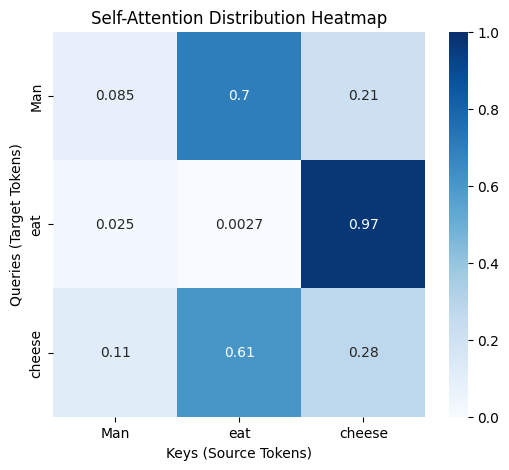

In [10]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    atten_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin = 0,
    vmax =1
)
plt.title("Self-Attention Distribution Heatmap")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.show()

In [11]:
# Explicitly show the math for step-by-step computation
for i, q_token in enumerate(tokens):
  print(f"\n--- Calculations for Query token: '{q_token}' ---")
  q_vec = Q[i]
  #1. Compute raw dot product with all keys
  raw_scores = []
  scaled_scores = []
  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_product = torch.dot(q_vec, k_vec).item()
    scaled_dot_product = dot_product / (d_k ** 0.5)
    raw_scores.append(dot_product)
    scaled_scores.append(scaled_dot_product)
    print(f"Key '{k_token}': Raw Dot Product = {dot_product:.4f}, Scaled (/{d_k ** 0.5:.2f}) = {scaled_dot_product:.4f}")

  #2 Compute Softmax manually to show distribution
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print("\n--- Softmax Distribution ---")
  for j, k_token in enumerate(tokens):
    print(f" {k_token}:exp({scaled_scores[j]:.4f}) / sum_exp = {probabilities[j]:.4e}")


--- Calculations for Query token: 'Man' ---
Key 'Man': Raw Dot Product = -10.2475, Scaled (/2.83) = -3.6230
Key 'eat': Raw Dot Product = -8.1395, Scaled (/2.83) = -2.8777
Key 'cheese': Raw Dot Product = -9.3275, Scaled (/2.83) = -3.2978

--- Softmax Distribution ---
 Man:exp(-3.6230) / sum_exp = 2.2265e-01
 eat:exp(-2.8777) / sum_exp = 4.6913e-01
 cheese:exp(-3.2978) / sum_exp = 3.0823e-01

--- Calculations for Query token: 'eat' ---
Key 'Man': Raw Dot Product = -10.3524, Scaled (/2.83) = -3.6601
Key 'eat': Raw Dot Product = -12.6044, Scaled (/2.83) = -4.4563
Key 'cheese': Raw Dot Product = -6.7101, Scaled (/2.83) = -2.3724

--- Softmax Distribution ---
 Man:exp(-3.6601) / sum_exp = 1.9702e-01
 eat:exp(-4.4563) / sum_exp = 8.8863e-02
 cheese:exp(-2.3724) / sum_exp = 7.1412e-01

--- Calculations for Query token: 'cheese' ---
Key 'Man': Raw Dot Product = -10.9490, Scaled (/2.83) = -3.8711
Key 'eat': Raw Dot Product = -9.2814, Scaled (/2.83) = -3.2815
Key 'cheese': Raw Dot Product = -10.

In [12]:
# Define multi-head attention dimensions
num_heads = 2
d_k_head = 8
d_v_head = 8

#Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)
#1 Linear Projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)
#2 Reshape to split into heads
Q_Split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
K_Split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
V_Split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0,1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_Split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_Split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_Split.shape)

Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 3, 8])


In [13]:
#3 Compute attention score & attention for each head independently
scores = torch.matmul(Q_Split, K_Split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_Split)
#4 Concatinate head outputs
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)
#5 Final linear projection
final_output = torch.matmul(concat_output, W_o)
print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)

Attention Distribution Shape (for all heads): torch.Size([2, 3, 3])
Concatenated Output Shape: torch.Size([3, 16])
Final Multi-head Attention Output Shape: torch.Size([3, 16])


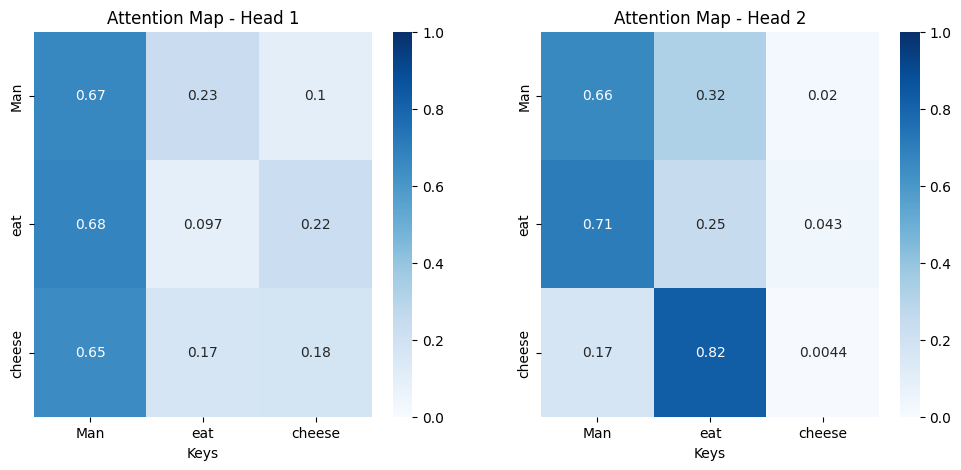

In [14]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))
for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmax=1,
        vmin=0,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")